#Practical week 5: custom data loaders, a CNN from scratch and visualising loss curves

The practical this week focusses on some low level practical issues that you will need to tackle in the assessment. We will see how to take an arbitrary dataset and write a custom data loader so that we can request random mini-batches during training like we did last week. Then you'll design and train your own CNN to learn a classification problem on the data. Working through this whole practical (which will definitely take more than the two hour lab session) is great practice for the assessment.

##This week's dataset

The task this week is to classify clothing images according to the type of garment. For this task, we're using the Fashion MNIST dataset. It's exactly the same format as the MNIST digits dataset we used last week (60k training images, 10k test images, 10 possible class labels, grayscale images of size $28\times 28$). See the code below for descriptions of the 10 classes.

Fashion MNIST is already set up as a dataset in PyTorch. However, we're going to pretend it's not so that you can experience writing your own custom data loader.

The following code will download and uncompress the training and testing datasets, then load them as PyTorch tensors. You'll have to do the rest.

In [ ]:
import torch
import os
import torchvision.datasets as datasets
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import math
import matplotlib.pyplot as plt

classes = ['T-shirt/top',
           'Trouser',
           'Pullover',
           'Dress',
           'Coat',
           'Sandal',
           'Shirt',
           'Sneaker',
           'Bag',
           'Ankle boot']
datafolder = 'fashion-mnist/'
os.makedirs(datafolder,exist_ok=True)

url = 'http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/'
files = ['train-images-idx3-ubyte','train-labels-idx1-ubyte','t10k-images-idx3-ubyte','t10k-labels-idx1-ubyte']
for f in files:
  datasets.utils.download_and_extract_archive(url+f+'.gz',datafolder)
data_train = datasets.mnist.read_image_file(datafolder+files[0])
labels_train = datasets.mnist.read_label_file(datafolder+files[1])
data_test = datasets.mnist.read_image_file(datafolder+files[2])
labels_test = datasets.mnist.read_label_file(datafolder+files[3])

The raw data is now loaded into tensors. Let's check we're happy with the shapes and contents.

In [ ]:
print('TRAINING DATA')
print(data_train.shape)
print('Minimum value: {}'.format(data_train.min()))
print('Maximum value: {}'.format(data_train.max()))
print(data_train.dtype)
print('TRAINING LABELS')
print(labels_train.shape)
print('Minimum value: {}'.format(labels_train.min()))
print('Maximum value: {}'.format(labels_train.max()))

Do the shapes of the two tensors make sense to you? One important note: we're storing the images currently as 8 bit integers to save space but we'll need to switch to floats for each mini-batch for training.

##Custom data loaders

`torch.utils.data.Dataset` is an abstract class for representing a dataset. To write a custom data loader you need to inherit `Dataset` and override two methods:

- `__len__` such that `len(dataset)` returns the number of elements in the dataset
- `__getitem__` such that `dataset[i]` can be used to get the $i$th element from the dataset

You can use the `__init__` constructor to set up your data. There are two common ways of constructing a data loader:

1. Read the entire dataset into memory inside `__init__`. If the dataset isn't too big so that you can hold the whole thing in memory then this is a good idea since `__getitem__` won't need to read anything from disc. (This option is fine for the dataset in this practical).
2. For larger datasets, `__init__` is just used to initialise where the dataset is stored and perhaps to read the labels into memory but no actual input data is loaded at this point. Then when `__getitem__` is called you actually load that specific item (for example an image) from disc.

Anything that `__len__` or `__getitem__` need access to should be stored in `self`.

**To do**:

Create a custom dataset whose constructor takes as input a size $n\times 28 \times 28$ tensor of images and size $n$ tensor of class labels. `__getitem__` should return a single image of size $1\times 28 \times 28$ as a 32 bit float scaled between 0 and 1 (hint: `x.float()/255` converts `x` from 8 bit integers to 0..1 floats) and the corresponding class label.

In [ ]:
class FashionMNISTDataset(Dataset):
  """Custom Fashion MNIST dataset."""

  def __init__(self, data, labels):
    # Your code goes here

  def __len__(self):
    # Your code goes here

  def __getitem__(self, idx):
    # Your code goes here
    return image, label

train_data = FashionMNISTDataset(data_train,labels_train)
test_data = FashionMNISTDataset(data_test,labels_test)

In [ ]:
# Solution

# C x H x W

class FashionMNISTDataset(Dataset):
  """Custom Fashion MNIST dataset."""

  def __init__(self, data, labels):
    self.data = data
    self.labels = labels

  def __len__(self):
    return self.data.shape[0]

  def __getitem__(self, idx):
    image = (self.data[idx,:,:].float()/255).unsqueeze(0)
    label = self.labels[idx]
    return image, label

train_data = FashionMNISTDataset(data_train,labels_train)
test_data = FashionMNISTDataset(data_test,labels_test)

Let's test whether your dataset is behaving as expected.

In [ ]:
image, label = train_data[0]
print(image.shape) # should be 1 x 28 x 28

##A validation set

So far we've only had training and test data. But we'll soon be using the loss curves to make decisions: when to stop training, which model to keep, whether to change the architecture or learning rate. If we make those decisions by looking at the test set, the test set is no longer an honest measure of how well the model will do on new data. So we hold out part of the training data as a **validation set** and make all our decisions with that. The test set is only used once, right at the end.

The code below takes a random 10,000 of the 60,000 training images as a validation set. We split the raw tensors and create a separate dataset object for each part (rather than using `torch.utils.data.random_split`) because later we'll want to apply data augmentation to the training images only.

In [ ]:
g = torch.Generator().manual_seed(0)   # fixed seed so the split is the same every time
perm = torch.randperm(len(labels_train), generator=g)
train_idx, val_idx = perm[:50000], perm[50000:]

train_data = FashionMNISTDataset(data_train[train_idx], labels_train[train_idx])
val_data = FashionMNISTDataset(data_train[val_idx], labels_train[val_idx])
test_data = FashionMNISTDataset(data_test, labels_test)
print(len(train_data), len(val_data), len(test_data))

Now we can create dataloaders from the three datasets.

In [ ]:
batch_size=100
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=True, num_workers=0)

Let's test them. Do these sizes look right?

In [ ]:
images, labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)

##Visualising the dataset

**To do**:

Look at last week's practical and copy the code for visualing images from a mini-batch. Run it with your dataloader to inspect the data. Now modify it so that it prints class descriptions as given above rather than class IDs.

In [ ]:
# Solution

images, labels = next(iter(train_loader))

figure = plt.figure(figsize=(10, 8))
cols, rows = 5, 5
for i in range(cols * rows):
    figure.add_subplot(rows, cols, i+1)
    plt.title(classes[labels[i]])
    plt.axis("off")
    plt.imshow(images[i,:].squeeze(), cmap="binary")
plt.show()

##Create a CNN

**To do**:

Now create a CNN to try to solve this classification performance. You could use the LeNet architecture from the last practical, the mini VGG I gave in my model solution or invent your own from scratch. Maybe you want to try batchnorm layers or even a residual block.

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Your code goes here...

    def forward(self,x):
        # Your code goes here...

# Instantiate the model - this initialises all weights and biases
model = CNN()

# Decide what loss function to use
#loss_func = ...

In [ ]:
# Solution

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.convlayers = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(6),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # B x 6 x 14 x 14 after this maxpool
            nn.Conv2d(in_channels=6, out_channels=12, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(12),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # B x 12 x 7 x 7 after this maxpool
            nn.Conv2d(in_channels=12, out_channels=24, kernel_size=3, stride=1, padding=0), # B x 24 x 5 x 5 after this conv
            nn.BatchNorm2d(24),
            nn.ReLU()
        )

        self.MLP = nn.Sequential(
            nn.Linear(in_features=5*5*24,out_features=120),
            nn.BatchNorm1d(120),
            nn.ReLU(),
            nn.Linear(in_features=120,out_features=84),
            nn.BatchNorm1d(84),
            nn.ReLU(),
            nn.Linear(in_features=84,out_features=10)
        )

    def forward(self, x):
        # Input x has dimensions B x 1 x 28 x 28, B is batch size
        x = self.convlayers(x)
        x = x.view(x.size(0), -1)
        x = self.MLP(x)
        # Output has dimensions B x 10
        return x

model = CNN()
loss_func = nn.CrossEntropyLoss()

In [ ]:
# Solution v2 (using Flatten() we can put the whole network into one Sequential())

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(6),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # B x 6 x 14 x 14 after this maxpool
            nn.Conv2d(in_channels=6, out_channels=12, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(12),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # B x 12 x 7 x 7 after this maxpool
            nn.Conv2d(in_channels=12, out_channels=24, kernel_size=3, stride=1, padding=0), # B x 24 x 5 x 5 after this conv
            nn.BatchNorm2d(24),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(in_features=5*5*24,out_features=120),
            nn.BatchNorm1d(120),
            nn.ReLU(),
            nn.Linear(in_features=120,out_features=84),
            nn.BatchNorm1d(84),
            nn.ReLU(),
            nn.Linear(in_features=84,out_features=10)
        )

    def forward(self, x):
        # Input x has dimensions B x 1 x 28 x 28, B is batch size
        x = self.net(x)
        # Output has dimensions B x 10
        return x

model = CNN()
loss_func = nn.CrossEntropyLoss()

It's interesting to see how many learnable parameters your model has in total:

In [ ]:
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(total_params)

Let's put a mini-batch through your CNN, compute a loss and check everything looks ok.

In [ ]:
images, labels = next(iter(train_loader))
output = model(images)
print(output.shape)
loss = loss_func(output,labels)
print(loss)

##Visualisation and training

It's time to train your network. The code below defines two functions. `evaluate` computes the average loss and accuracy over a whole data loader. `train_model` trains for a number of epochs and, after every epoch, records the loss and accuracy on both the training and validation sets so that we can plot training curves.

**Early stopping** (video 2): rather than keeping the weights from the last epoch, we keep the weights from the epoch where the validation loss was lowest.

**To do**: complete the early stopping lines in `train_model` (marked "To do"). Then run the following cells to train your network and plot the training curves.

In [ ]:
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def evaluate(model, loader):
  """Average loss and classification accuracy of model over every batch in loader."""
  model.eval()   # switch batchnorm (and dropout) to evaluation mode
  total_loss, correct, total = 0, 0, 0
  with torch.no_grad():
    for inputs, labels in loader:
      inputs, labels = inputs.to(device), labels.to(device)
      output = model(inputs)
      total_loss += loss_func(output, labels).item() * inputs.shape[0]
      correct += (torch.argmax(output, 1) == labels).sum().item()
      total += inputs.shape[0]
  model.train()  # switch back to training mode
  return total_loss / total, correct / total

def train_model(model, optim, num_epochs, train_loader, val_loader):
  """Train model, tracking training and validation loss/accuracy every epoch. Returns a dictionary of curves."""
  history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
  best_val_loss = float('inf')
  best_epoch = None
  best_state = None
  iterations_per_epoch = len(train_loader)
  for epoch in range(num_epochs):

    # One epoch on the training set
    total_loss, correct, total = 0, 0, 0
    for i, (inputs, labels) in enumerate(train_loader):
      inputs, labels = inputs.to(device), labels.to(device)
      output = model(inputs)
      loss = loss_func(output, labels)
      optim.zero_grad()
      loss.backward()
      optim.step()
      total_loss += loss.item() * inputs.shape[0]
      correct += (torch.argmax(output, 1) == labels).sum().item()
      total += inputs.shape[0]
      if (i+1) % 100 == 0:
        print('Epoch [{}/{}], Iteration [{}/{}], Loss: {:.4f}'.format(epoch + 1, num_epochs, i + 1, iterations_per_epoch, loss.item()))
    history['train_loss'].append(total_loss / total)
    history['train_acc'].append(correct / total)

    # One pass over the validation set
    val_loss, val_acc = evaluate(model, val_loader)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    print('Epoch {}: training accuracy {:.4f}, validation accuracy {:.4f}, validation loss {:.4f}'.format(
        epoch + 1, history['train_acc'][-1], val_acc, val_loss))

    # Early stopping: remember the weights from the epoch with the lowest validation loss
    if val_loss < best_val_loss:
      best_val_loss = val_loss
      best_epoch = epoch
      best_state = copy.deepcopy(model.state_dict())   # deepcopy, otherwise we'd just keep a reference to weights that keep changing

  # Put the best weights back into the model
  if best_state is not None:
    model.load_state_dict(best_state)
    print('Restored the weights from epoch {} (validation loss {:.4f})'.format(best_epoch + 1, best_val_loss))
  history['best_epoch'] = best_epoch
  return history

In [ ]:
model = model.to(device)
num_epochs = 20
optim = torch.optim.Adam(model.parameters(), lr = 0.01)
history = train_model(model, optim, num_epochs, train_loader, val_loader)

In [ ]:
def plot_history(history, title=''):
  epochs = range(1, len(history['train_loss']) + 1)
  fig, axes = plt.subplots(1, 2, figsize=(12, 4))
  axes[0].plot(epochs, history['train_loss'], 'r', label='training')
  axes[0].plot(epochs, history['val_loss'], 'g', label='validation')
  axes[0].set_ylabel('Loss')
  axes[1].plot(epochs, history['train_acc'], 'r', label='training')
  axes[1].plot(epochs, history['val_acc'], 'g', label='validation')
  axes[1].set_ylabel('Classification accuracy')
  for ax, name in zip(axes, ['Training curve', 'Classification accuracy']):
    if history.get('best_epoch') is not None:
      ax.axvline(history['best_epoch'] + 1, color='grey', linestyle=':', label='lowest validation loss')
    ax.set_xlabel('Epoch')
    ax.set_title((title + ' ' + name).strip())
    ax.legend()
  plt.show()

plot_history(history)

What do you make of the plots? Has training converged yet? Is your model too powerful? (i.e. is overfitting happening?) Or not powerful enough? (Performance not improving much). Tweak your model or hyperparameters if you think there's a problem.

Where is the validation loss lowest? If the training loss keeps falling while the validation loss starts to rise, the model is overfitting (video 2). You may also see the validation accuracy stay roughly flat while the validation loss rises: the model is becoming over-confident about the examples it gets wrong. Early stopping keeps the weights from the best epoch.

**To do**:

- Try plotting training loss at every iteration rather than just every epoch. Why does it look so different?
- Reuse the visualisation code from last week to show example images along with their correct/estimate class.
- You've probably noticed that training is starting to take a while. Try switching to using a GPU (see lecture slides for instructions).




In [ ]:
# Run a test batch through the network
images, labels = next(iter(test_loader))
images,labels = images.to(device), labels.to(device)
output = model(images)
pred_y = torch.argmax(output, 1)

# Display first 25 images with predicted labels
figure = plt.figure(figsize=(10, 8))
for i in range(25):
    figure.add_subplot(5, 5, i+1)
    plt.title("{}/{}".format(classes[labels[i]],classes[pred_y[i]]))
    plt.axis("off")
    plt.imshow(images[i,:].squeeze().cpu(), cmap="gray")
plt.show()

###Evaluating on the test set

Only now, after every decision (architecture, learning rate, when to stop) has been made using the validation set, do we evaluate on the test set. Do this once, at the end.

In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print('Test loss {:.4f}, test accuracy {:.4f}'.format(test_loss, test_acc))

##Data augmentation

Video 1 introduced data augmentation: every time a training image is used, apply a small random change that doesn't change its label. The network effectively sees a different version of each image every epoch, which makes it much harder to memorise the training set.

Your custom dataset is the natural place to do this, inside `__getitem__`. PyTorch datasets usually take an optional `transform` argument for exactly this purpose. We'll use two random transforms from `torchvision.transforms`: a horizontal flip (with probability 0.5) and a random shift of up to 2 pixels in each direction (pad the image by 2 pixels, then crop a random $28\times 28$ window).

**To do**:

1. Add an optional `transform` argument to your `FashionMNISTDataset` class (default `None`). If it isn't `None`, apply it to the image in `__getitem__` after converting it to a float tensor.
2. Create an augmented version of the **training** set only, `train_data_aug`, and a data loader for it, `train_loader_aug`. Leave the validation and test sets unaugmented: we want to measure performance on real images.
3. Run the cell below that shows several random augmentations of the same image, to check it's working.
4. Train a fresh copy of your CNN on the augmented data with the same optimiser settings and number of epochs, then compare its training curves with your first run.
5. Is a horizontal flip a sensible augmentation for Fashion-MNIST? Would it be for MNIST digits?

In [ ]:
# Solution

import torchvision.transforms as transforms

augment = transforms.Compose([
    transforms.RandomHorizontalFlip(),      # mirror left-right with probability 0.5
    transforms.RandomCrop(28, padding=2),   # pad by 2 pixels then crop back to 28x28: a random shift
])

class FashionMNISTDataset(Dataset):
  """Custom Fashion MNIST dataset with an optional transform."""

  def __init__(self, data, labels, transform=None):
    self.data = data
    self.labels = labels
    self.transform = transform

  def __len__(self):
    return self.data.shape[0]

  def __getitem__(self, idx):
    image = (self.data[idx,:,:].float()/255).unsqueeze(0)
    if self.transform is not None:
      image = self.transform(image)   # a different random transform every time this image is requested
    label = self.labels[idx]
    return image, label

train_data_aug = FashionMNISTDataset(data_train[train_idx], labels_train[train_idx], transform=augment)
train_loader_aug = torch.utils.data.DataLoader(train_data_aug, batch_size=batch_size, shuffle=True, num_workers=0)

In [ ]:
# The same training image, requested 8 times: a different random augmentation each time
figure = plt.figure(figsize=(12, 2))
for i in range(8):
    image, label = train_data_aug[1]
    figure.add_subplot(1, 8, i+1)
    plt.axis("off")
    plt.imshow(image.squeeze(), cmap="gray")
plt.suptitle(classes[label])
plt.show()

In [ ]:
# Solution

torch.manual_seed(0)
model_aug = CNN().to(device)
optim = torch.optim.Adam(model_aug.parameters(), lr = 0.01)
history_aug = train_model(model_aug, optim, num_epochs, train_loader_aug, val_loader)
plot_history(history_aug, 'With augmentation:')

plt.plot(range(1, num_epochs + 1), history['val_loss'], label='no augmentation')
plt.plot(range(1, num_epochs + 1), history_aug['val_loss'], label='with augmentation')
plt.xlabel('Epoch'); plt.ylabel('Validation loss'); plt.legend(); plt.show()

test_loss, test_acc = evaluate(model_aug, test_loader)
print('With augmentation: test loss {:.4f}, test accuracy {:.4f}'.format(test_loss, test_acc))

With augmentation the validation loss should keep falling for much longer, with little or no sign of overfitting within 20 epochs, and the lowest validation loss should be a little lower. Don't expect a big jump in test accuracy: on this dataset the main benefit is that you can train for longer without overfitting. Notice also that the training loss is now measured on augmented images, which are harder than the real ones, so it no longer drops far below the validation loss.

Horizontal flips are fine for clothing (a mirrored shoe is still a shoe), but not for digits: a mirrored 3 is not a 3, and some flipped digits look like other digits. Good augmentations depend on the problem.

##Comparing optimisers (optional)

Video 4 introduced momentum, AdaGrad, RMSProp and Adam.

**To do**: train three fresh copies of your CNN for 10 epochs each, using

- plain SGD with `lr=0.1`
- SGD with momentum, `lr=0.01, momentum=0.9`
- Adam with `lr=0.001`

and plot their validation losses on one graph. Call `torch.manual_seed(0)` before creating each model so that all three start from the same initial weights.

Bear in mind that each optimiser has its own range of good learning rates, so a fair comparison would tune the learning rate separately for each one (as we discussed in the Week 3 review session). Try a couple of other learning rates if you have time.

In [ ]:
# Solution

optimisers = {
    'SGD, lr 0.1': lambda params: torch.optim.SGD(params, lr=0.1),
    'SGD with momentum 0.9, lr 0.01': lambda params: torch.optim.SGD(params, lr=0.01, momentum=0.9),
    'Adam, lr 0.001': lambda params: torch.optim.Adam(params, lr=0.001),
}
histories = {}
for name, make_optimiser in optimisers.items():
  print(name)
  torch.manual_seed(0)
  m = CNN().to(device)
  histories[name] = train_model(m, make_optimiser(m.parameters()), 10, train_loader, val_loader)

for name, h in histories.items():
  plt.plot(range(1, 11), h['val_loss'], label=name)
plt.xlabel('Epoch'); plt.ylabel('Validation loss'); plt.legend(); plt.show()

##Implement a ResNet (optional)

Take any of the problems you've worked on over the past couple of weeks (e.g. MNIST digit or fashion classification) and try implementing your own resnet architecture to solve it. Usually, this would start with a convolutional layer to transform from the one input channel to some larger number of features then residual blocks which contain a number of convolutional layers applied in sequence. You might like to define a residual block as its own `nn.Module` then you can define your network using `nn.Sequential` including your new blocks. Instead of pooling, it is more common to use strided convolutions. Also, instead of fully connected layers at the end, it is more common to use global average pooling (i.e. pooling with kernel size equal to spatial dimensions). If your residual block changes the size of tensor either spatially or in number of channels, then you need to apply some kind of downsampling to the residual connection. How does your model compare to the other networks we tried?

###Solution

Here is a relatively basic implementation. This hopefully illustrates a few ideas for how you could implement a resnet from scratch. But I haven't tuned any hyperparameters or architectural decisions so it could surely be improved a lot.

In [ ]:
class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride):
        super(ResBlock, self).__init__()
        self.convblock = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=3, stride=stride, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=3, stride=1, padding='same'),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )
        self.downsample = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=1, stride=stride),
            nn.BatchNorm2d(out_channels)
        )

    def forward(self, x):
      identity = self.downsample(x)
      x = self.convblock(x)
      x = x+identity
      return x

In [ ]:
class TinyResNet(nn.Module):
    def __init__(self):
        super(TinyResNet, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU()
        self.resnet = nn.Sequential(
            ResBlock(16,32,2),
            ResBlock(32,64,2)
        )
        self.globalpool = nn.AvgPool2d(kernel_size=7)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(in_features=64,out_features=10)

    def forward(self, x):
      x = self.conv1(x)
      x = self.bn1(x)
      x = self.relu(x)
      x = self.resnet(x)
      x = self.globalpool(x)
      x = self.flatten(x)
      x = self.fc1(x)
      return x
model = TinyResNet()

In [ ]:
# Put some random data through to check sizes look correct
x = torch.randn(100,1,28,28)
y = model(x)
print(y.shape)

In [ ]:
# Count number of trainable parameters in network to compare with other models
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(total_params)

##An extra challenge: fully convolutional LeNet

If you would like an extra challenge to work on, try this...

As was pointed out in [this paper](https://arxiv.org/pdf/1605.06211.pdf), a CNN that includes fully connected layers can be thought of as having only convolution layers. The fully connected layers are just a special case where the filter size is $1\times 1$. Start by training a modified version of LeNet in which you replace the fully connected (i.e. `torch.nn.Linear`) layers with convolutions. To do this you need to:

1. Delete the flattening operation in the forward pass (that reshapes from $B\times 16 \times 5 \times 5$ to $B\times 400$).
2. In the original LeNet, the second convolution uses no padding which shrinks the feature map by two pixels vertically and horizontally. This is undesirable for a fully convolutional network as it means regions at the boundary are treated differently. So, let's scrap that and use `padding=2` like in the first convolution layer.
3. The first linear layer should be replaced by a convolution. Originally, the feature map at this point would have size $5\times 5$ but because we just added padding, it will now have size $7\times 7$. So, for this new convolution layer use kernel size $7\times 7$ and no padding. We also want to only consider each region independently and not the overlaps between them so set `stride=7`. This is now exactly equivalent to flattening followed by a fully connected layer. It's a special case where the filter exactly spatially covers the input. The output size of this tensor will be $B\times 120 \times 1 \times 1$, i.e. it has spatial size $1\times 1$ and 120 channels.
4. The second and third linear layers should be replaced with convolution layers with kernel size $1\times 1$ and no padding and the appropriate number of input and output channels.
5. The final output will now have size $B\times 10 \times 1 \times 1$. Before passing to the loss function, you need to squeeze to size $B\times 10$.

You can now train the model exactly as before. However, once trained, you should be able to input images with size different to $28\times 28$. The output will no longer have size $10\times 1\times 1$. For example, if you input an image of size $56\times 56$, the output will be size $10\times 2\times 2$. At each of the four locations, you will get 10 values related to how likely it thinks each digit is at that location.

Download the following image:

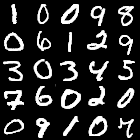

Upload it to your notebook's session storage and load it. The recommended way to read images is using `PIL.Image`. The torchvision transform `ToTensor` will convert this to a PyTorch tensor. E.g. see the following example:

In [ ]:
from PIL import Image
import torchvision.transforms as transforms

transform = transforms.ToTensor()
im = transform(Image.open('filename.png'))
# im is now a C x H x W PyTorch tensor

Pass the image through your trained network. Apply softmax to the output to convert to probabilities. Now visualise the output as $5\times 5$ heat maps. For example, try visualising the first channel (representing the probability of a 0 digit). Do you see large probability where the zeros in the image are?

###Solution

In [ ]:
from torchvision.transforms import ToTensor
train_data = datasets.MNIST(root = 'data', train = True, transform = ToTensor(), download = True)
test_data = datasets.MNIST(root = 'data', train = False, transform = ToTensor())
train_loader = torch.utils.data.DataLoader(train_data, batch_size=100, shuffle=True, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=100, shuffle=True, num_workers=0)

In [ ]:
# Version 1: follows the specific instructions in the practical and ends up outputting one prediction for each 28x28 input block

class FullyConvLeNet(nn.Module):
    def __init__(self):
        super(FullyConvLeNet, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding='same')
        self.sigmoid = nn.Tanh() # LeCun actually uses hyperbolic tangent, though the paper talks about "sigmoidal function"
        self.meanpool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1, padding='same')
        self.fc1 = nn.Conv2d(in_channels=16, out_channels=120, kernel_size=7, stride=7, padding=0)
        self.fc2 = nn.Conv2d(in_channels=120, out_channels=84, kernel_size=1, stride=1, padding=0)
        self.fc3 = nn.Conv2d(in_channels=84, out_channels=10, kernel_size=1, stride=1, padding=0)

    def forward(self, x):
        # Input x has dimensions B x 1 x H x W, B is batch size
        # Comments show tensor size output from previous line
        x = self.conv1(x)
        # B x 6 x H x W
        x = self.sigmoid(x)
        x = self.meanpool(x)
        # B x 6 x H/2 x W/2
        x = self.conv2(x)
        # B x 16 x H/2 x W/2
        x = self.sigmoid(x)
        x = self.meanpool(x)
        # B x 16 x H/4 x W/4
        x = self.fc1(x)
        # B x 120 x 1 x 1
        x = self.sigmoid(x)
        x = self.fc2(x)
        # B x 84 x 1 x 1
        x = self.sigmoid(x)
        x = self.fc3(x)
        # B x 10 x 1 x 1
        return x

# Instantiate the model - this initialises all weights and biases
model = FullyConvLeNet()

In [ ]:
# Version 2: a direct translation of LeNet to fully convolutional - will output spatial predictions for intermediate positions

class FullyConvLeNet(nn.Module):
    def __init__(self):
        super(FullyConvLeNet, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding='same')
        self.sigmoid = nn.Tanh() # LeCun actually uses hyperbolic tangent, though the paper talks about "sigmoidal function"
        self.meanpool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1, padding=0)
        self.fc1 = nn.Conv2d(in_channels=16, out_channels=120, kernel_size=5, stride=1, padding=0)
        self.fc2 = nn.Conv2d(in_channels=120, out_channels=84, kernel_size=1, stride=1, padding=0)
        self.fc3 = nn.Conv2d(in_channels=84, out_channels=10, kernel_size=1, stride=1, padding=0)

    def forward(self, x):
        # Input x has dimensions B x 1 x H x W, B is batch size
        # Comments show tensor size output from previous line
        x = self.conv1(x)
        # B x 6 x H x W
        x = self.sigmoid(x)
        x = self.meanpool(x)
        # B x 6 x H/2 x W/2
        x = self.conv2(x)
        # B x 16 x H/2 x W/2
        x = self.sigmoid(x)
        x = self.meanpool(x)
        # B x 16 x H/4 x W/4
        x = self.fc1(x)
        # B x 120 x 1 x 1
        x = self.sigmoid(x)
        x = self.fc2(x)
        # B x 84 x 1 x 1
        x = self.sigmoid(x)
        x = self.fc3(x)
        # B x 10 x 1 x 1
        return x

# Instantiate the model - this initialises all weights and biases
model = FullyConvLeNet()

In [ ]:
x = torch.randn(100,1,140,140)
y = model(x)
print(y.shape)

In [ ]:
# Test one batch
images, labels = next(iter(train_loader))
output = model(images)
print(output.shape)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

num_epochs = 10

optim = torch.optim.SGD(model.parameters(), lr = 0.1)
iterations_per_epoch = len(train_loader)

# Set up the loss function for multiclass classification
loss_func = nn.CrossEntropyLoss()

for epoch in range(num_epochs):
  total_loss = 0
  for i, (images, labels) in enumerate(train_loader):
    images, labels = images.to(device), labels.to(device)
    output = model(images)
    loss = loss_func(output.squeeze(3).squeeze(2),labels)
    optim.zero_grad()
    loss.backward()
    optim.step()
    if (i+1) % 100 == 0:
       print('Epoch [{}/{}], Iteration [{}/{}], Loss: {:.4f}'.format(epoch + 1, num_epochs, i + 1, iterations_per_epoch, loss.item()))
    total_loss += loss
  print('Total loss over epoch {}: {:.2f}'.format(epoch+1,total_loss))

In [ ]:
from PIL import Image
import torchvision.transforms as transforms

transform = transforms.ToTensor()
im = transform(Image.open('MNIST_grid.png'))
print(im.shape)

In [ ]:
output = model(im.unsqueeze(0).to(device))
print(output.shape) # Depending which version of the network you used, this will be 5x5 or larger
probs = nn.functional.softmax(output,dim=1)
plt.imshow(probs[0,7,:,:].cpu().detach().numpy())